In [45]:
import pandas as pd
import numpy as np

print(f"Pandas version: {pd.__version__}")
print(f"NumPy version: {np.__version__}")

Pandas version: 3.0.5
NumPy version: 2.4.6


<h1>Lodaing The Dataset<h1>

In [46]:
# Load with MultiIndex headers (two rows of headers)
df = pd.read_excel('../data/raw/SEERA_cost_estimation_dataset.xlsx', header=[0, 1],keep_default_na=False, na_values="?" )

print("Dataset loaded successfully!")
print(f"Shape: {df.shape} rows x {df.shape[1]} columns")

Dataset loaded successfully!
Shape: (120, 76) rows x 76 columns


<h1> Dataset Structure</h1>

In [47]:
df.info

<bound method DataFrame.info of     General Information                                                    \
                 ProjID Year of project Organization id Organization type   
0                     1            2015               1                 1   
1                     2            2016              25                 5   
2                     3            2008               2                 5   
3                     4            2009              42                 4   
4                     5            2016              42                 4   
..                  ...             ...             ...               ...   
115                 116            2018              38                 1   
116                 117            1998               4                 4   
117                 118            2006              14                 2   
118                 119            2016              43                 6   
119                 120            2016     

In [3]:
print("Column structure (MultiIndex):")
print(df.columns)

Column structure (MultiIndex):
MultiIndex([('General Information', ...),
            ('General Information', ...),
            ('General Information', ...),
            ('General Information', ...),
            ('General Information', ...),
            ('General Information', ...),
            ('General Information', ...),
            ('General Information', ...),
            ('General Information', ...),
            ('General Information', ...),
            ('General Information', ...),
            ('General Information', ...),
            ('General Information', ...),
            (               'Size', ...),
            (               'Size', ...),
            (               'Size', ...),
            (             'Effort', ...),
            (             'Effort', ...),
            (        'Environment', ...),
            (        'Environment', ...),
            (        'Environment', ...),
            (        'Environment', ...),
            (        'Environment', ...),
   

<b>Flattening the columns for easier viewing<b>

In [48]:
df_flattened = df.copy()
df_flattened.columns = ['_'.join(col).strip() for col in df.columns.values]
print("Flattened column names:")
print(df_flattened.columns.tolist())

Flattened column names:
['General Information_ProjID', 'General Information_Year of project', 'General Information_Organization id', 'General Information_Organization type', 'General Information_Role in organization', 'General Information_Size of organization', 'General Information_Size of IT department', 'General Information_Customer organization type', 'General Information_Estimated  duration', 'General Information_Actual duration', 'General Information_% project gain (loss)', 'General Information_Development type', 'General Information_Application domain', 'Size_Object points', 'Size_Other sizing method', 'Size_Estimated size', 'Effort_Estimated effort', 'Effort_Actual effort', 'Environment_Contract maturity', 'Environment_Government policy impact', 'Environment_Economic instability impact', 'Environment_Organization management structure clarity', 'Environment_Developer hiring policy', 'Environment_Developer incentives policy', 'Environment_Developer training', 'Environment_Developm

<b>Data types</b>

In [49]:
print("Data types:")
print(df.dtypes)

Data types:
General Information  ProjID                        int64
                     Year of project               int64
                     Organization id               int64
                     Organization type             int64
                     Role in organization          int64
                                                  ...   
Product              Performance requirements    float64
                     Product complexity          float64
                     Security requirements       float64
                     Reliability requirements    float64
                     Specified H/W               float64
Length: 76, dtype: object


<b>Data types summary</b>

In [6]:
print("Data type summary:")
df.info()
print(df.dtypes.value_counts())

Data type summary:
<class 'pandas.DataFrame'>
RangeIndex: 120 entries, 0 to 119
Data columns (total 76 columns):
 #   Column                                                        Non-Null Count  Dtype  
---  ------                                                        --------------  -----  
 0   (General Information, ProjID)                                 120 non-null    int64  
 1   (General Information, Year of project)                        120 non-null    int64  
 2   (General Information, Organization id)                        120 non-null    int64  
 3   (General Information, Organization type)                      120 non-null    int64  
 4   (General Information, Role in organization)                   120 non-null    int64  
 5   (General Information, Size of organization)                   120 non-null    object 
 6   (General Information, Size of IT department)                  120 non-null    object 
 7   (General Information, Customer organization type)             1

<ol>
<h2><li>Missing Values</li></h2>

In [50]:
missing_placeholders = ["?", " ", "N/A", "n/a", "None", "null", "-", ""]
df_clean = df.replace(missing_placeholders, np.nan)
total_missing = df_clean.isna().sum().sum()
total_cells = df_clean.size
overall_missing_pct = (total_missing / total_cells) * 100

print(f"=== OVERALL DATASET SUMMARY ===")
print(f"Total Missing Values: {total_missing} out of {total_cells} cells ({overall_missing_pct:.2f}%)\n")

m = df.isnull().sum().sum()
print(f"===  DATASET Missing values ===")
print(f"Missing Values:{m} out of {total_cells}\n")

=== OVERALL DATASET SUMMARY ===
Total Missing Values: 455 out of 9120 cells (4.99%)

===  DATASET Missing values ===
Missing Values:109 out of 9120



In [5]:
print("Missing values per column:")
missing_data = df.isnull().sum().sort_values(ascending=False)
print(missing_data[missing_data > 0])
overall_missing_pct = (missing_data.sum() / total_cells) * 100
print(f"Overall Missing Values: {missing_data.sum()} out of {total_cells} cells ({overall_missing_pct:.2f}%)\n")

Missing values per column:
General Information  % project gain (loss)                             39
Developers           Team contracts                                    11
Product              Requirement accuracy level                         4
General Information  Customer organization type                         4
Project              Process reengineering                              3
Product              Product complexity                                 3
Environment          Organization management structure clarity          2
Size                 Object points                                      2
Project              Degree of software reuse                           2
Environment          Developer training                                 2
Product              Reliability requirements                           2
                     Specified H/W                                      2
Developers           Income satisfaction                                2
Product    

In [51]:
na_not_applicable = (df == "N/A").sum()
print("Columns with 'N/A' values:")
print(na_not_applicable[na_not_applicable > 0])

Columns with 'N/A' values:
General Information  Size of organization           8
                     Size of IT department          8
                     % project gain (loss)         17
Size                 Estimated size               107
Project              Outsourcing impact           108
                     Degree of standards usage     98
dtype: int64


In [7]:
missing_percent = (df.isnull().sum())/len(df)*100
print("Percentage of missing values per column:")
print(missing_percent[missing_percent > 0].sort_values(ascending=False))

Percentage of missing values per column:
General Information  % project gain (loss)                             32.500000
Developers           Team contracts                                     9.166667
General Information  Customer organization type                         3.333333
Product              Requirement accuracy level                         3.333333
Project              Process reengineering                              2.500000
Product              Product complexity                                 2.500000
Project              Degree of software reuse                           1.666667
Environment          Organization management structure clarity          1.666667
                     Developer training                                 1.666667
Developers           Income satisfaction                                1.666667
Size                 Object points                                      1.666667
Product              Comments within the code                       

<Axes: title={'center': 'Percentage of Missing Values'}>

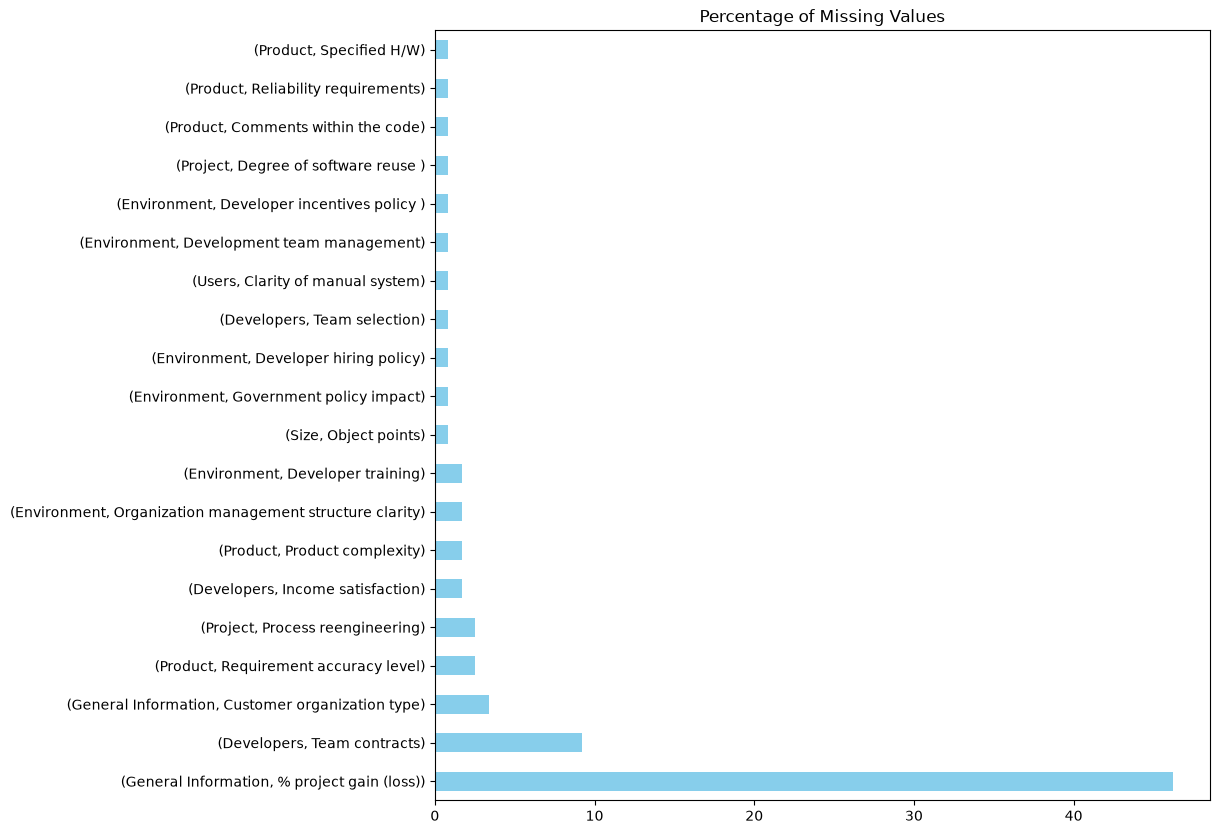

In [52]:
missing_percent[missing_percent > 0].sort_values(ascending=False).plot(kind='barh', color='skyblue', title='Percentage of Missing Values', figsize=(10, 10))

In [9]:
import missingno as msno
import matplotlib.pyplot as plt

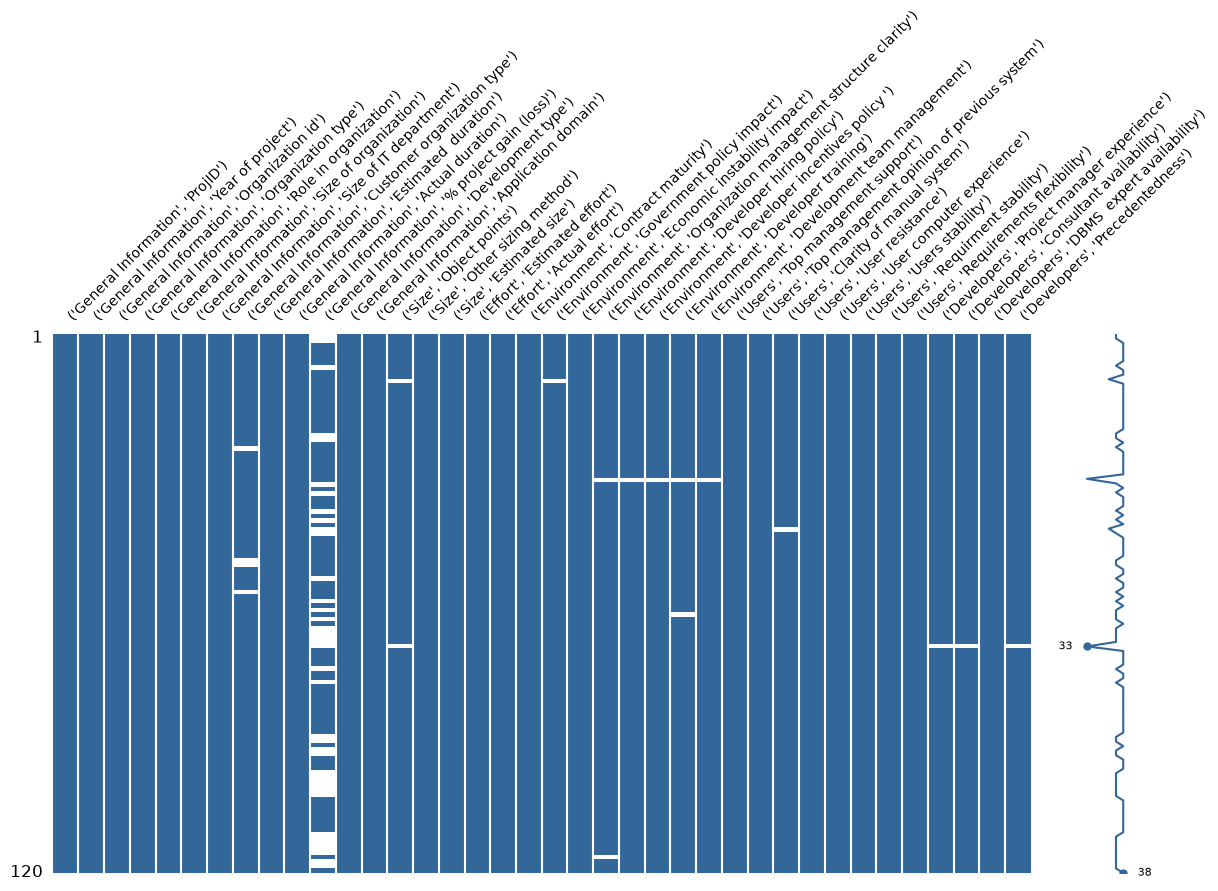

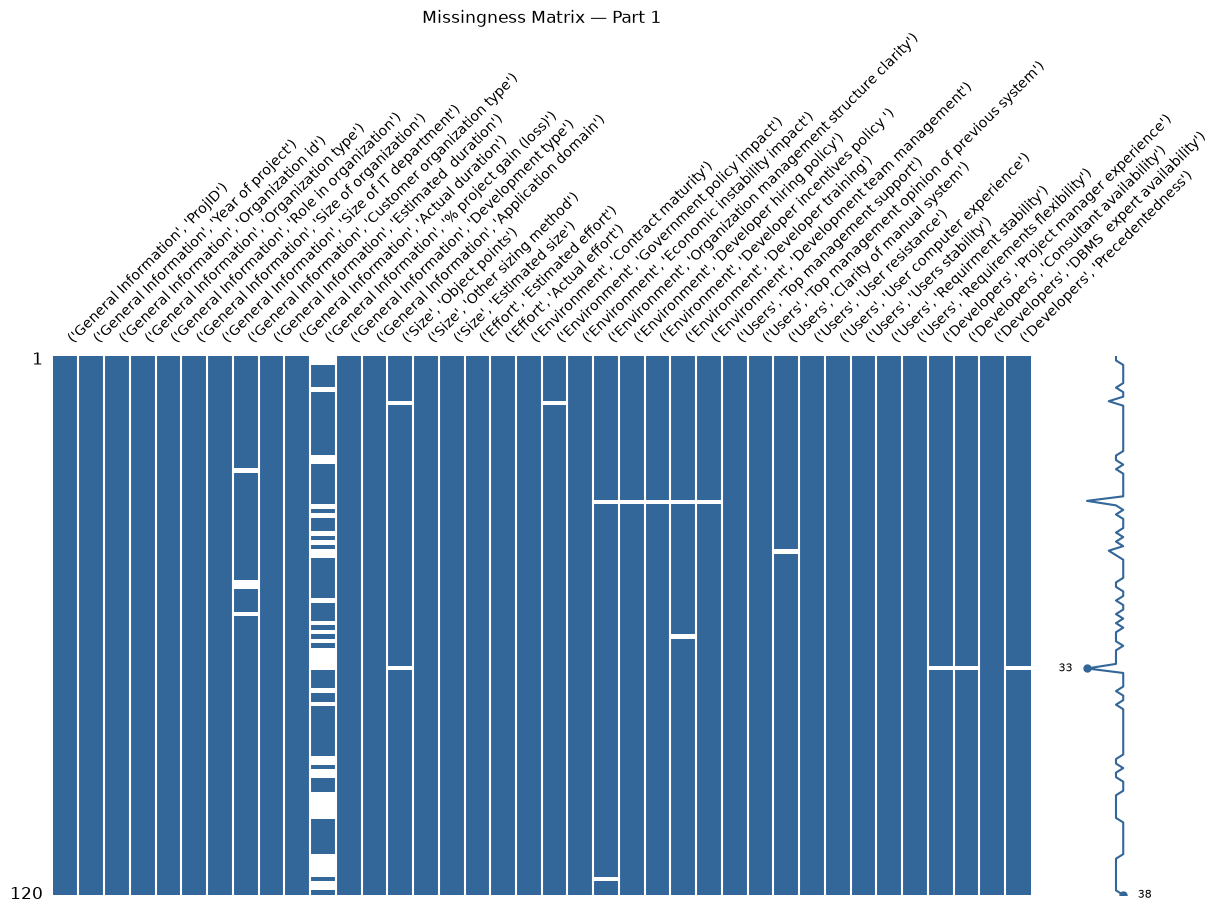

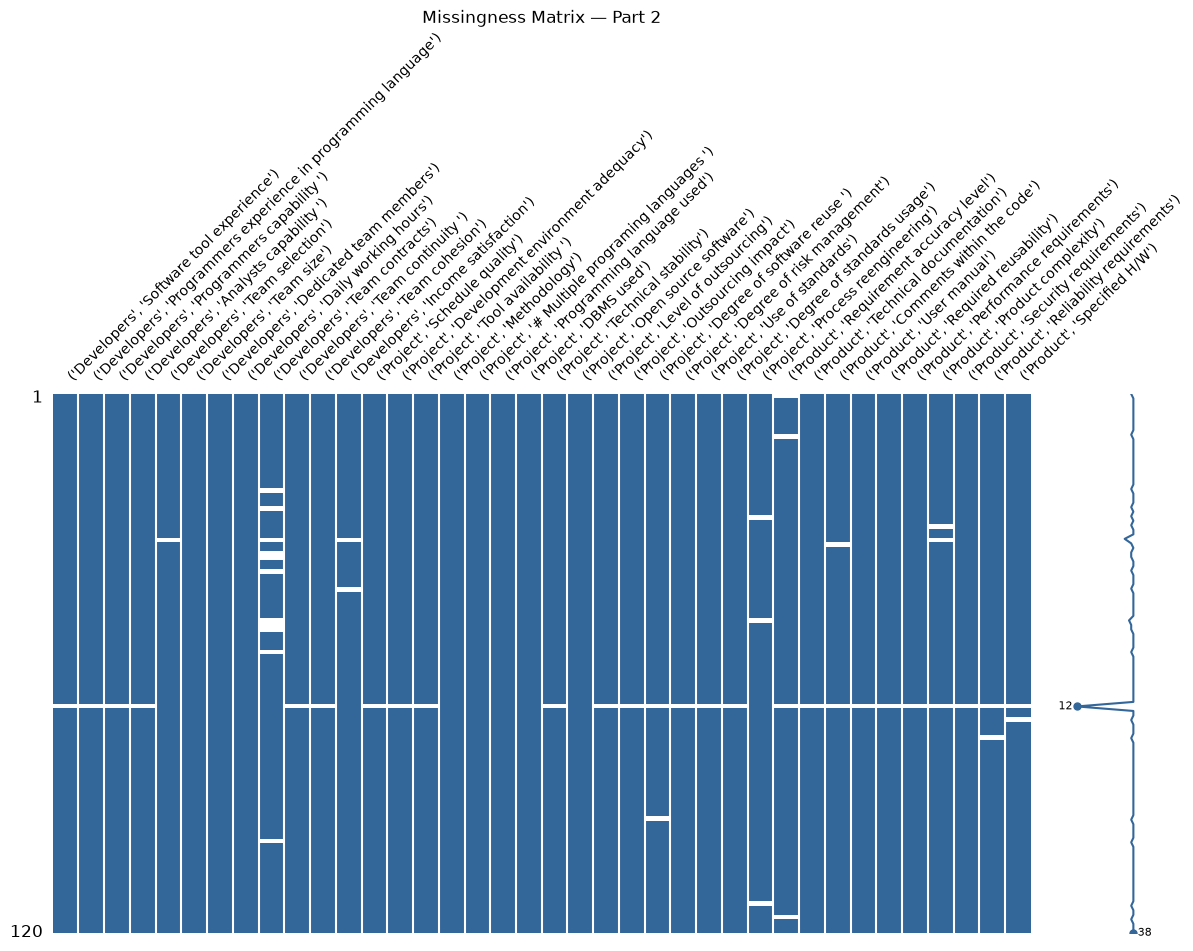

In [32]:
half = len(df.columns) // 2
cols_1 = df.columns[:half]
cols_2 = df.columns[half:]

msno.matrix(df[cols_1], figsize=(14, 7), fontsize=10, color=(0.2, 0.4, 0.6))
msno.matrix(df[cols_1], figsize=(14, 7), fontsize=10, color=(0.2, 0.4, 0.6))
plt.title("Missingness Matrix — Part 1")
msno.matrix(df[cols_2], figsize=(14, 7), fontsize=10, color=(0.2, 0.4, 0.6))
plt.title("Missingness Matrix — Part 2")
plt.show()

In [18]:
import plotly.express as px

In [33]:
# 1. Filter to only columns that actually have missing values
missing_percent = (df.isnull().sum()) / len(df) * 100
cols_with_missing = missing_percent[missing_percent > 0].index

# 2. Flatten MultiIndex columns to readable strings
flat_labels = ['_'.join(col).strip() for col in cols_with_missing]

# 3. Create a binary DataFrame (1 = present, 0 = missing) for just those columns
missing_df = df[cols_with_missing].notnull().astype(int)
missing_df.columns = flat_labels

# 4. Plot as an interactive heatmap
fig = px.imshow(
    missing_df,
    labels=dict(x="Columns", y="Row Index", color="Data Present"),
    x=flat_labels,
    color_continuous_scale=["#ffffff", "#2b2b2b"],  # white = missing, dark = present
    title="Interactive Missing Data Map",
    aspect="auto"
)

# 5. Readable hover text: map 0/1 to Missing/Present
fig.update_traces(
    customdata=missing_df.replace({1: "Present", 0: "Missing"}).values,
    hovertemplate="Row: %{y}<br>Column: %{x}<br>Status: %{customdata}<extra></extra>"
)

# 6. Improve layout readability
fig.update_layout(
    xaxis_tickangle=-45,
    width=1200,
    height=700
)
fig.show()

In [10]:
print("---Row 69 data, has the most missing values:---")
df.iloc[69]

---Row 69 data, has the most missing values:---


General Information  ProjID                        70
                     Year of project             2018
                     Organization id               19
                     Organization type              8
                     Role in organization           2
                                                 ... 
Product              Performance requirements     NaN
                     Product complexity           NaN
                     Security requirements        NaN
                     Reliability requirements     NaN
                     Specified H/W                NaN
Name: 69, Length: 76, dtype: object

<h4>Deleting the 69 row </h4>

In [53]:
df.drop(df.index[69], inplace=True)

<h3>N/A Values </h3>

In [54]:
# 1. Size of IT department — check if N/A rows correspond to Organization type
#    likely to lack an IT department (e.g. Freelancer, per the codebook)
org_type_col = ('General Information', 'Organization type')
it_size_col = ('General Information', 'Size of IT department')

na_it_rows = df_flattened_original[df_flattened_original[it_size_col] == "N/A"] if False else None
# use the original df before replacement — reload or use a copy that still has "N/A" as string
na_mask = df[it_size_col].astype(str) == "N/A"
print("Organization type for rows where IT dept size = N/A:")
print(df.loc[na_mask, org_type_col].value_counts())

# 2. Size of organization — check if there's any legitimate N/A code in the schema
#    (per the PDF, "Organization size" table has no N/A option — so any N/A here
#    is likely genuine missing data, not structural)
size_col = ('General Information', 'Size of organization')
na_mask_size = df[size_col].astype(str) == "N/A"
print(f"\nRows with 'N/A' in Size of organization: {na_mask_size.sum()}")
print(df.loc[na_mask_size, org_type_col].value_counts())

# 3. % project gain (loss) — check if N/A rows correspond to missing effort values
gain_loss_col = ('General Information', '% project gain (loss)')
est_col = ('Effort', 'Estimated effort')
act_col = ('Effort', 'Actual effort')

na_mask_gain = df[gain_loss_col].astype(str) == "N/A"
print(f"\nRows with 'N/A' in % project gain (loss): {na_mask_gain.sum()}")
print(df.loc[na_mask_gain, [est_col, act_col]])

Organization type for rows where IT dept size = N/A:
(General Information, Organization type)
7    5
5    3
Name: count, dtype: int64

Rows with 'N/A' in Size of organization: 8
(General Information, Organization type)
7    5
5    3
Name: count, dtype: int64

Rows with 'N/A' in % project gain (loss): 17
              Effort              
    Estimated effort Actual effort
12               880        1760.0
13              1848        3080.0
14              1584        2112.0
15              1320        2640.0
16               880        1760.0
17               264         396.0
18              2772        5544.0
34              1584        3168.0
75             11264       18304.0
103             8910       14850.0
104            10692       17820.0
105             5346        5346.0
106            10692       10692.0
107            10692       10692.0
108             8019        8019.0
109            14256       10692.0
110             8019       10692.0


<h3>Handling N/A</h3>

In [55]:
# Size of IT department & Size of organization: N/A is STRUCTURAL (not applicable),
# not missing data. Keep it as its own explicit category rather than converting to NaN,
# so CatBoost treats it as a valid, informative category (e.g. "no formal IT department").
it_size_col = ('General Information', 'Size of IT department')
org_size_col = ('General Information', 'Size of organization')

df[it_size_col] = df[it_size_col].replace("N/A", "No_IT_Department")
df[org_size_col] = df[org_size_col].replace("N/A", "No_Formal_Size")

# % project gain (loss): N/A here is TRUE missing data (confirmed — Estimated/Actual
# effort were present in all 17 N/A rows, ruling out a structural/derived cause).
# Convert to real NaN so it's captured correctly in any future missingness handling.
gain_loss_col = ('General Information', '% project gain (loss)')
df[gain_loss_col] = df[gain_loss_col].replace("N/A", pd.NA)

# Sanity check: confirm no more literal "N/A" strings remain anywhere
remaining_na_strings = (df == "N/A").sum()
print("Any remaining 'N/A' strings:")
print(remaining_na_strings[remaining_na_strings > 0])

Any remaining 'N/A' strings:
Size     Estimated size               106
Project  Outsourcing impact           108
         Degree of standards usage     98
dtype: int64


In [56]:
# Hypothesis 1: "Outsourcing impact" = N/A exactly when "Level of outsourcing" = "No outsourcing"
outsourcing_level_col = ('Project', 'Level of outsourcing')
outsourcing_impact_col = ('Project', 'Outsourcing impact')

na_mask = df[outsourcing_impact_col] == "N/A"
print("Level of outsourcing, where Outsourcing impact = N/A:")
print(df.loc[na_mask, outsourcing_level_col].value_counts(dropna=False))

# Hypothesis 2: "Degree of standards usage" = N/A exactly when "Use of standards" = "Not using any standards"
standards_use_col = ('Project', 'Use of standards')
standards_degree_col = ('Project', 'Degree of standards usage')

na_mask2 = df[standards_degree_col] == "N/A"
print("\nUse of standards, where Degree of standards usage = N/A:")
print(df.loc[na_mask2, standards_use_col].value_counts(dropna=False))

# Hypothesis 3: "Estimated size" = N/A when a different sizing method (e.g. Object points) was used instead
sizing_method_col = ('Size', 'Other sizing method')
object_points_col = ('Size', 'Object points')
est_size_col = ('Size', 'Estimated size')

na_mask3 = df[est_size_col] == "N/A"
print("\nOther sizing method, where Estimated size = N/A:")
print(df.loc[na_mask3, sizing_method_col].value_counts(dropna=False))
print("\nObject points, where Estimated size = N/A (checking if Object points was used instead):")
print(df.loc[na_mask3, object_points_col].isnull().value_counts())

Level of outsourcing, where Outsourcing impact = N/A:
(Project, Level of outsourcing)
3.0    108
Name: count, dtype: int64

Use of standards, where Degree of standards usage = N/A:
(Project, Use of standards)
3.0    98
Name: count, dtype: int64

Other sizing method, where Estimated size = N/A:
(Size, Other sizing method)
2    105
5      1
Name: count, dtype: int64

Object points, where Estimated size = N/A (checking if Object points was used instead):
(Size, Object points)
False    106
Name: count, dtype: int64


In [57]:
outsourcing_impact_col = ('Project', 'Outsourcing impact')
standards_degree_col = ('Project', 'Degree of standards usage')
est_size_col = ('Size', 'Estimated size')

# Confirmed structural — replace with an explicit "not applicable" category
df[outsourcing_impact_col] = df[outsourcing_impact_col].replace("N/A", "No_Outsourcing_Used")
df[standards_degree_col] = df[standards_degree_col].replace("N/A", "No_Standards_Used")

# Estimated size: 106/107 structural, 1 genuine exception.
# Resolve the 106 structural rows first...
object_points_col = ('Size', 'Object points')
structural_mask = (df[est_size_col] == "N/A") & (df[object_points_col].notnull())
df.loc[structural_mask, est_size_col] = "Sized_By_Object_Points"

# ...then the 1 remaining true-missing row converts to real NaN
df[est_size_col] = df[est_size_col].replace("N/A", pd.NA)

# Final check — should now be zero
remaining = (df == "N/A").sum()
print(remaining[remaining > 0])

Series([], dtype: int64)


In [58]:
na_not_applicable = (df == "N/A").sum()
print("Columns with 'N/A' values:")
print(na_not_applicable[na_not_applicable > 0])

Columns with 'N/A' values:
Series([], dtype: int64)


In [59]:
missing_placeholders = ["?", " ", "N/A", "n/a", "None", "null", "-", ""]
df_clean = df.replace(missing_placeholders, np.nan)
total_missing = df_clean.isna().sum().sum()
total_cells = df_clean.size
overall_missing_pct = (total_missing / total_cells) * 100

print(f"=== OVERALL DATASET SUMMARY ===")
print(f"Total Missing Values: {total_missing} out of {total_cells} cells ({overall_missing_pct:.2f}%)\n")

m = df.isnull().sum().sum()
print(f"===  DATASET Missing values ===")
print(f"Missing Values:{m} out of {total_cells}\n")

=== OVERALL DATASET SUMMARY ===
Total Missing Values: 95 out of 9044 cells (1.05%)

===  DATASET Missing values ===
Missing Values:95 out of 9044



In [60]:
print("Missing values per column:")
print(df.isnull().sum().sort_values(ascending=False))
missing_percent = (df.isnull().sum())/len(df)*100
print("Percentage of missing values per column:")
print(missing_percent[missing_percent > 0].sort_values(ascending=False))

Missing values per column:
General Information  % project gain (loss)         55
Developers           Team contracts                11
General Information  Customer organization type     4
Product              Requirement accuracy level     3
Project              Process reengineering          3
                                                   ..
                     Use of standards               0
Product              Performance requirements       0
                     Required reusability           0
                     User manual                    0
                     Security requirements          0
Length: 76, dtype: int64
Percentage of missing values per column:
General Information  % project gain (loss)                        46.218487
Developers           Team contracts                                9.243697
General Information  Customer organization type                    3.361345
Product              Requirement accuracy level                    2.521008
Project  

<h4>Dropping the % project gain (loss) column </h4>

In [61]:
df.drop(columns=[('General Information', '% project gain (loss)')], inplace=True)

<h4>Checking the missing values after dropping the % project gain (loss) column: </h4>

In [62]:
missing_placeholders = ["?", " ", "N/A", "n/a", "None", "null", "-", ""]
df_clean = df.replace(missing_placeholders, np.nan)
total_missing = df_clean.isna().sum().sum()
total_cells = df_clean.size
overall_missing_pct = (total_missing / total_cells) * 100

print(f"=== OVERALL DATASET SUMMARY ===")
print(f"Total Missing Values: {total_missing} out of {total_cells} cells ({overall_missing_pct:.2f}%)\n")

m = df.isnull().sum().sum()
print(f"===  DATASET Missing values ===")
print(f"Missing Values:{m} out of {total_cells}\n")

=== OVERALL DATASET SUMMARY ===
Total Missing Values: 40 out of 8925 cells (0.45%)

===  DATASET Missing values ===
Missing Values:40 out of 8925



<h2>2. Outliers</h2>
To calculate the outliers, we used the IQR method <br>
We check only continuos columns

In [11]:
def profile_outliers_safe(df, columns=None):
    """
    Safely analyzes outliers column-by-column, ignoring non-numeric features.
    """
    # If no columns specified, automatically pick only numeric ones
    if columns is None:
        columns = df.select_dtypes(include=[np.number]).columns.tolist()
        
    analysis_results = []
    
    for col in columns:
        if col in df.columns:
            # CHECK: Skip if the column is text, category, object, or boolean
            if not np.issubdtype(df[col].dtype, np.number):
                print(f"Skipping column '{col}': It is not numerical ({df[col].dtype}).")
                continue
                
            # IQR Boundary Calculations
            Q1 = df[col].quantile(0.25)
            Q3 = df[col].quantile(0.75)
            IQR = Q3 - Q1
            lower_bound = Q1 - 1.5 * IQR
            upper_bound = Q3 + 1.5 * IQR
            
            # Isolate outliers
            outlier_mask = (df[col] < lower_bound) | (df[col] > upper_bound)
            outliers_series = df.loc[outlier_mask, col]
            
            analysis_results.append({
                'Column': col,
                'Outlier Count': int(outlier_mask.sum()),
                'Sum of Outliers': float(outliers_series.sum()),
                'Actual Values': outliers_series.tolist()
            })
            
    return pd.DataFrame(analysis_results)
continuous_columns = [
    ('General Information', 'Year of project'),
    ('General Information', 'Estimated  duration'),
    ('General Information', 'Actual duration'),
    ('Size', 'Object points'),
    ('Effort', 'Estimated effort'),
    ('Effort', 'Actual effort'),
    ('Developers', 'Team size'),
    ('Developers', 'Dedicated team members'),
    ('Developers', 'Daily working hours'),
    ('Developers', 'Team continuity ')
]

outlier_data = profile_outliers_safe(df, continuous_columns)
print("=== OUTLIER ANALYSIS REPORT ===")
for col, info in outlier_data.iterrows():
     print(f"Column indexed#{col} {info['Column']}: Found {info['Outlier Count']} outliers.")
     print(f" -> Actual Values: {info['Actual Values']}\n")

=== OUTLIER ANALYSIS REPORT ===
Column indexed#0 ('General Information', 'Year of project'): Found 2 outliers.
 -> Actual Values: [1994, 1993]

Column indexed#1 ('General Information', 'Estimated  duration'): Found 3 outliers.
 -> Actual Values: [20.0, 15.0, 18.0]

Column indexed#2 ('General Information', 'Actual duration'): Found 12 outliers.
 -> Actual Values: [24.0, 45.0, 36.0, 25.0, 24.0, 24.0, 36.0, 24.0, 36.0, 48.0, 24.0, 36.0]

Column indexed#3 ('Size', 'Object points'): Found 3 outliers.
 -> Actual Values: [1100.0, 800.0, 1700.0]

Column indexed#4 ('Effort', 'Estimated effort'): Found 8 outliers.
 -> Actual Values: [19008, 50688, 25344, 14784, 17600, 26928, 31680, 14256]

Column indexed#5 ('Effort', 'Actual effort'): Found 11 outliers.
 -> Actual Values: [38016.0, 24255.0, 35640.0, 76032.0, 29040.0, 38016.0, 22176.0, 28160.0, 44880.0, 33792.0, 79200.0]

Column indexed#6 ('Developers', 'Team size'): Found 9 outliers.
 -> Actual Values: [48, 12, 12, 12, 11, 25, 18, 12, 45]

Colum

<h2>3. Unique Values</h2>

In [ ]:
pd.set_option('display.max_rows', None)
pd.set_option('display.max_columns', None)
df.nunique(dropna=False).sort_values()

In [19]:
df.nunique(dropna=False)[df.nunique(dropna=False) == 1]

Series([], dtype: int64)

In [17]:
for col in df.columns:
    print(f"\n--- {col} ---")
    print(df[col].value_counts(dropna=False).head(15))


--- ('General Information', 'ProjID') ---
(General Information, ProjID)
1     1
2     1
3     1
4     1
5     1
6     1
7     1
8     1
9     1
10    1
11    1
12    1
13    1
14    1
15    1
Name: count, dtype: int64

--- ('General Information', 'Year of project') ---
(General Information, Year of project)
2016    19
2018    15
2017    12
2015     8
2009     7
2014     7
2012     6
2006     6
2013     5
2019     5
2001     4
2008     3
2010     3
2011     3
2004     3
Name: count, dtype: int64

--- ('General Information', 'Organization id') ---
(General Information, Organization id)
11    16
6     11
42     8
3      8
5      8
14     6
8      4
13     4
18     4
35     4
2      3
7      3
9      3
4      2
12     2
Name: count, dtype: int64

--- ('General Information', 'Organization type') ---
(General Information, Organization type)
5    65
4    26
2     8
3     6
7     5
1     4
8     4
6     2
Name: count, dtype: int64

--- ('General Information', 'Role in organization') ---
(Gene

<h3>Handling Constants: </h3>

In [62]:
constant_cols = df.nunique(dropna=False)
constant_cols = constant_cols[constant_cols == 1].index.tolist()
print(f"Found {len(constant_cols)} constant column(s):")
for col in constant_cols:
    print(f"  {col}: value = {df[col].iloc[0]}")

Found 0 constant column(s):


<h2>4. Duplicates</h2>

In [18]:
df.duplicated().sum()

np.int64(0)

<h2>5. Leakage</h2>

<h2> 6. Columns inspection: categrical columns</h2>

In [35]:
# Categorical/options attributes explicitly documented in the
# SEERA_dataset__sub_attribute_codes.pdf, matched to the actual
# MultiIndex column names (including exact spacing) in df.

categorical_columns = [
    # General Information
    ("General Information", "Organization type"),
    ("General Information", "Role in organization"),
    ("General Information", "Customer organization type"),
    ("General Information", "Size of organization"),
    ("General Information", "Size of IT department"),
    ("General Information", "Application domain"),
    ("General Information", "Development type"),

    # Environment
    ("Environment", "Government policy impact"),
    ("Environment", "Developer hiring policy"),
    ("Environment", "Organization management structure clarity"),
    ("Environment", "Developer incentives policy "),   # trailing space in df
    ("Environment", "Developer training"),

    # Users
    ("Users", "Top management opinion of previous system"),
    ("Users", "Clarity of manual system"),
    ("Users", "User computer experience"),
    ("Users", "Users stability"),
    ("Users", "Requirements flexibility"),

    # Developers
    ("Developers", "Project manager experience"),
    ("Developers", "Consultant availability"),
    ("Developers", "DBMS  expert availability"),        # double space in df
    ("Developers", "Software tool experience"),
    ("Developers", "Programmers experience in programming language"),
    ("Developers", "Team selection"),
    ("Developers", "Income satisfaction"),

    # Project
    ("Project", "Schedule quality"),
    ("Project", "Programming language used"),
    ("Project", "DBMS used"),
    ("Project", "Methodology"),
    ("Project", "Technical stability"),
    ("Project", "Open source software"),
    ("Project", "Level of outsourcing"),
    ("Project", "Outsourcing impact"),
    ("Project", "Degree of software reuse "),           # trailing space in df
    ("Project", "Use of standards"),
    ("Project", "Process reengineering"),

    # Product
    ("Product", "Requirement accuracy level"),
    ("Product", "Technical documentation"),
    ("Product", "Comments within the code"),
    ("Product", "User manual"),
    ("Product", "Required reusability"),
    ("Product", "Product complexity"),
    ("Product", "Reliability requirements"),
    ("Product", "Specified H/W"),
]

for col in categorical_columns:
    if col in df.columns:
        print(f"\n--- {col} ---")
        counts = df[col].value_counts(dropna=False)
        percentages = df[col].value_counts(dropna=False, normalize=True) * 100
    
        print(pd.DataFrame({
            "Count": counts,
            "Percentage": percentages.round(2)}))
    else:
        print(f"\nColumn not found in df: {col}")

# Columns not documented in this codes PDF — verify their coding
# in the main SEERA documentation before treating as categorical.
undocumented = [
    ("Environment", "Contract maturity"),
    ("Environment", "Economic instability impact"),
    ("Environment", "Development team management"),
    ("Users", "Top management support"),
    ("Users", "User resistance"),
    ("Users", "Requirment stability"),
    ("Developers", "Precedentedness"),
    ("Developers", "Programmers capability "),
    ("Developers", "Analysts capability "),
    ("Developers", "Team contracts"),
    ("Developers", "Team continuity "),
    ("Developers", "Team cohesion"),
    ("Project", "Development environment adequacy"),
    ("Project", "Tool availability "),
    ("Project", "Degree of risk management"),
    ("Project", "Degree of standards usage"),
    ("Product", "Performance requirements"),
    ("Product", "Security requirements"),
]
print("\n\n=== Columns NOT covered in this codes file (check separately) ===")
for col in undocumented:
    if col in df.columns:
        print(col)


--- ('General Information', 'Organization type') ---
                                          Count  Percentage
(General Information, Organization type)                   
5                                            65       54.17
4                                            26       21.67
2                                             8        6.67
3                                             6        5.00
7                                             5        4.17
1                                             4        3.33
8                                             4        3.33
6                                             2        1.67

--- ('General Information', 'Role in organization') ---
                                             Count  Percentage
(General Information, Role in organization)                   
2                                               76       63.33
1                                               32       26.67
4                                    

<h2> 7. Actual Effort: Target Variable Analysis</h2>

In [44]:
actual_effort = df[("Effort", "Actual effort")]

print(f"Mean of actual effort is: {actual_effort.mean():.2f}")
print(f"Median is: {actual_effort.median():.2f}")
print(f"Mode value is: {actual_effort.mode().iloc[0]:.2f}")


Mean of actual effort is: 9060.93
Median is: 4576.00
Mode value is: 3168.00


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

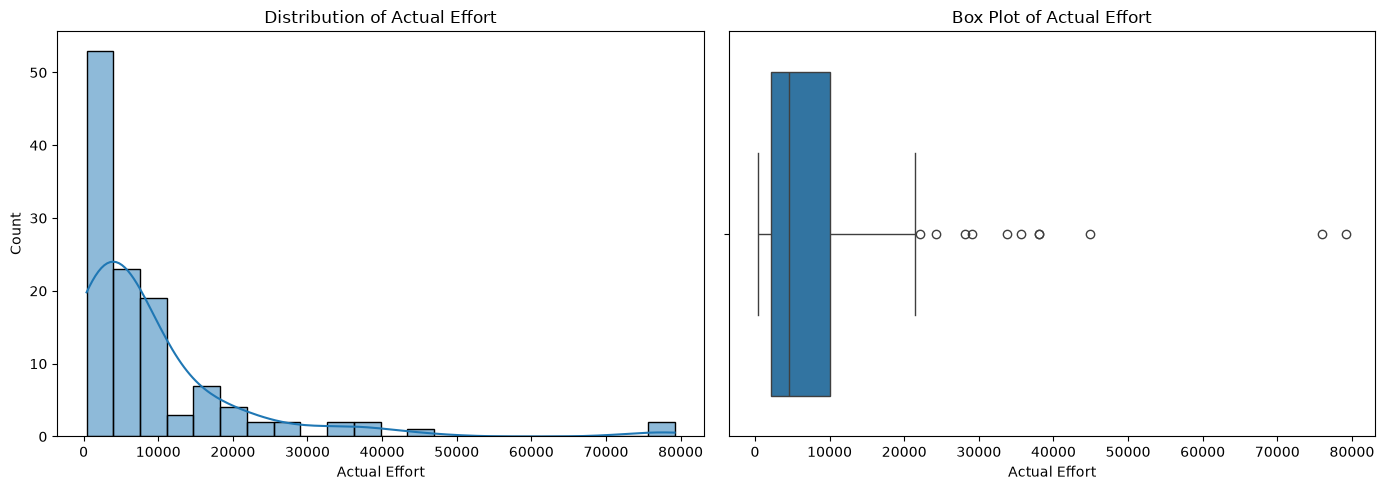

In [58]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(df[("Effort", "Actual effort")].dropna(), kde=True, ax=axes[0])
axes[0].set_title('Distribution of Actual Effort')
axes[0].set_xlabel('Actual Effort')

sns.boxplot(x=df[("Effort", "Actual effort")].dropna(), ax=axes[1])
axes[1].set_title('Box Plot of Actual Effort')
axes[1].set_xlabel('Actual Effort')
plt.tight_layout()
plt.show()

In [60]:
from scipy.stats import skew, kurtosis

In [62]:
target_skew = df[("Effort", "Actual effort")].dropna().skew()
target_kurt = df[("Effort", "Actual effort")].dropna().kurtosis()

print(f"Skewness: {target_skew:.3f}")
print(f"Kurtosis: {target_kurt:.3f}")

Skewness: 3.345
Kurtosis: 14.067


Min value: 396.0
Values <= 0: 0


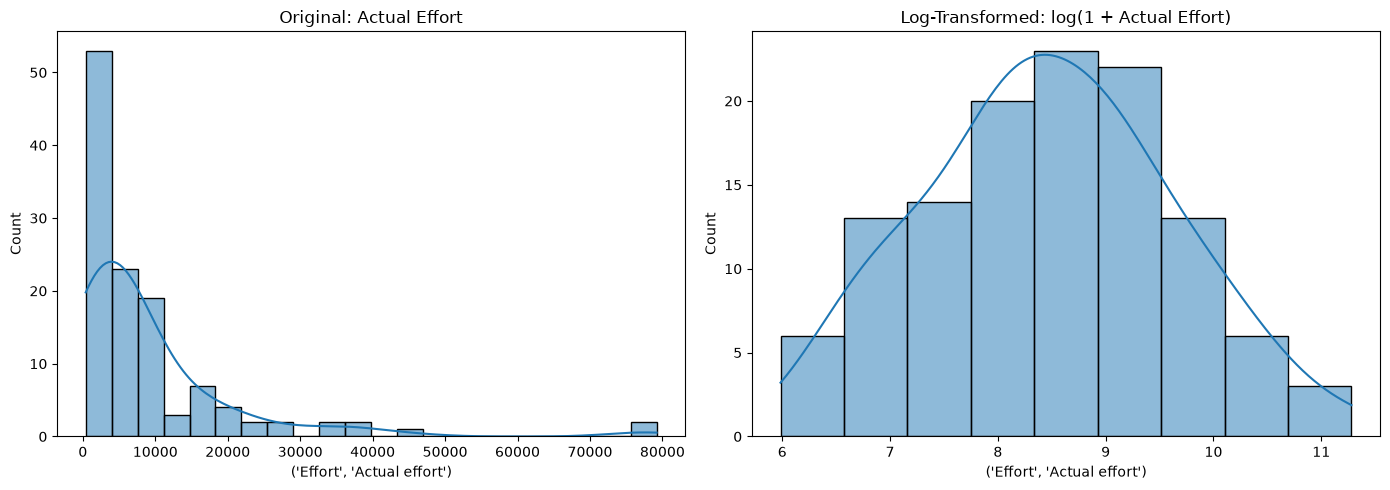

Original skewness: 3.345
Log-transformed skewness: 0.097


In [63]:
# Check for zero/negative values first (step 5, do this before log)
print(f"Min value: {df[('Effort', 'Actual effort')].min()}")
print(f"Values <= 0: {(df[('Effort', 'Actual effort')] <= 0).sum()}")

# Apply log1p and compare
log_effort = np.log1p(df[("Effort", "Actual effort")].dropna())

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(df[("Effort", "Actual effort")].dropna(), kde=True, ax=axes[0])
axes[0].set_title('Original: Actual Effort')

sns.histplot(log_effort, kde=True, ax=axes[1])
axes[1].set_title('Log-Transformed: log(1 + Actual Effort)')

plt.tight_layout()
plt.show()

log_skew = log_effort.skew()
print(f"Original skewness: {target_skew:.3f}")
print(f"Log-transformed skewness: {log_skew:.3f}")

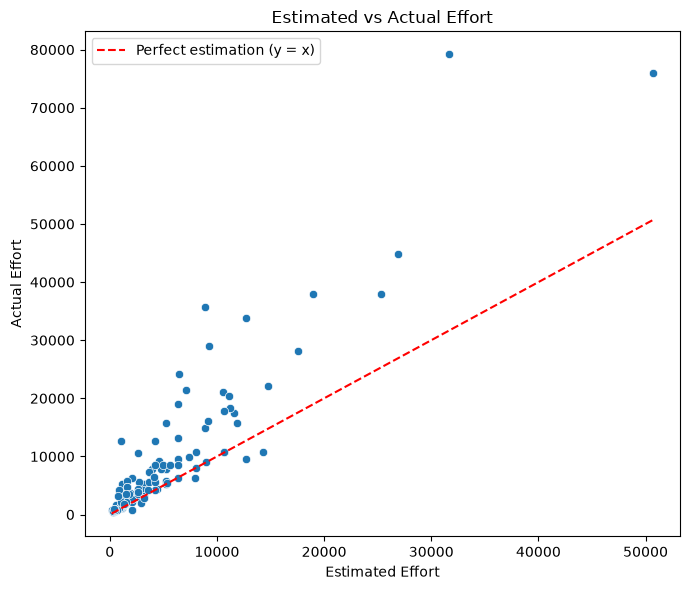

count     81
unique    31
top        0
freq      30
Name: (General Information, % project gain (loss)), dtype: int64


In [65]:
est_col = ('Effort', 'Estimated effort')

fig, ax = plt.subplots(figsize=(7, 6))
sns.scatterplot(x=df[est_col], y=df[("Effort", "Actual effort")], ax=ax)
ax.plot([df[est_col].min(), df[est_col].max()],
        [df[est_col].min(), df[est_col].max()],
        'r--', label='Perfect estimation (y = x)')
ax.set_xlabel('Estimated Effort')
ax.set_ylabel('Actual Effort')
ax.set_title('Estimated vs Actual Effort')
ax.legend()
plt.tight_layout()
plt.show()

# Quick numeric check using existing column
gain_loss_col = ('General Information', '% project gain (loss)')
print(df[gain_loss_col].describe())

In [66]:
gain_loss_col = ('General Information', '% project gain (loss)')
print(df[gain_loss_col].unique())

[nan 0 -0.16666666666666666 -0.17444444444444446 -0.25 'N/A'
 0.6296296296296297 -1.0215633423180592 0.16647058823529412 0.25 0.2 -1
 -0.04352941176470588 0.036470588235294116 0.05647058823529412
 -1.2222222222222223 0.026470588235294117 0.4533333333333333
 0.11647058823529412 0.08647058823529412 -0.013529411764705882
 0.4115384615384615 -0.21212121212121213 -0.13333333333333333 0.43
 0.07647058823529412 0.09375 0.5 -0.14285714285714285 0.3333333333333333
 -0.2222222222222222 -1.5]


<h2>8. Correlation Analysis:</h2>

In [47]:
import seaborn as sns

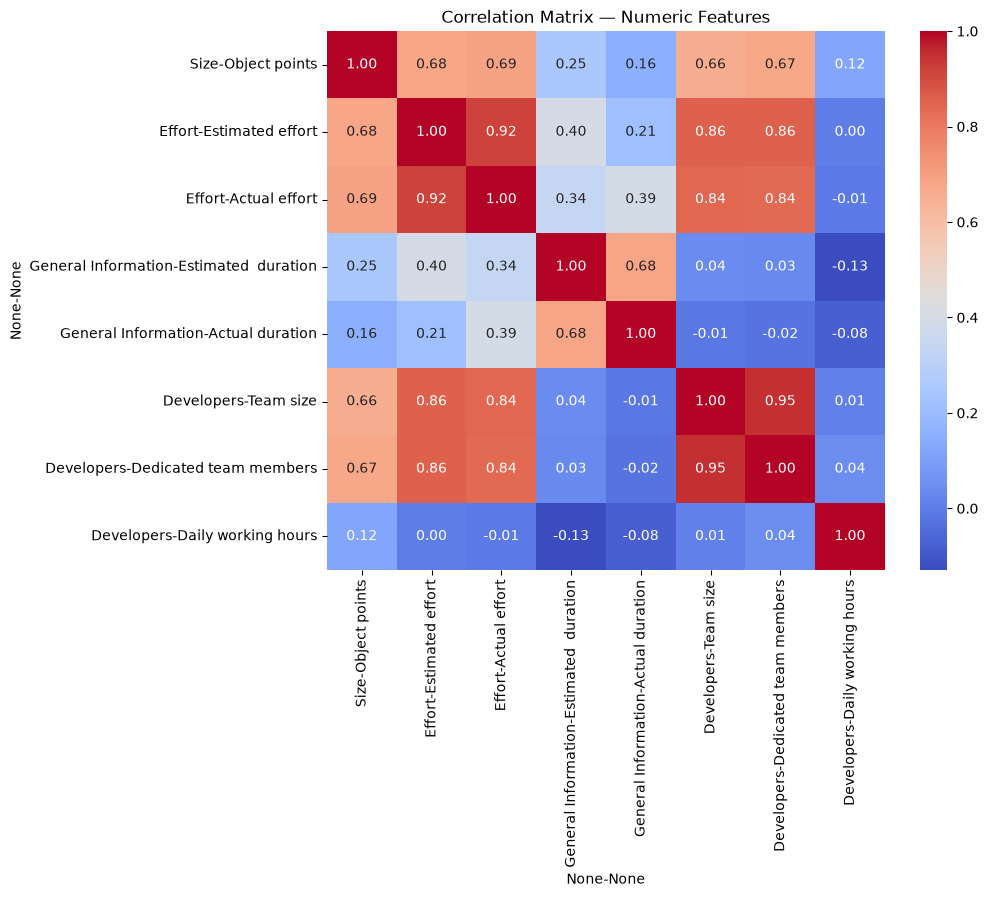

In [56]:
numeric_cols = [
    ("Size", "Object points"),
    ("Effort", "Estimated effort"),
    ("Effort", "Actual effort"),
    ("General Information", "Estimated  duration"),
    ("General Information", "Actual duration"),
    ("Developers", "Team size"),
    ("Developers", "Dedicated team members"),
    ("Developers", "Daily working hours"),
]

plt.figure(figsize=(9, 7))
sns.heatmap(df[numeric_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", cbar=True)
plt.title("Correlation Matrix — Numeric Features")
plt.show()

<h2>Skip this </h2>

In [ ]:
pip install dice-ml --break-system-packages

In [36]:
import dice_ml
from dice_ml import Dice

In [39]:
from catboost import CatBoostRegressor
target_col = '_'.join(act_col)

X = df_flattened.drop(columns=[target_col]).dropna()
y = df_flattened.loc[X.index, target_col]

model = CatBoostRegressor(verbose=0)
model.fit(X, y)

CatBoostRegressor(loss_function='RMSE', verbose=0)

In [43]:
continuous_candidates = X.select_dtypes(include=[np.number]).columns.tolist()
print(continuous_candidates)

['General Information_ProjID', 'General Information_Year of project', 'General Information_Organization id', 'General Information_Organization type', 'General Information_Role in organization', 'General Information_Customer organization type', 'General Information_Estimated  duration', 'General Information_Actual duration', 'General Information_Development type', 'General Information_Application domain', 'Size_Object points', 'Size_Other sizing method', 'Effort_Estimated effort', 'Environment_Contract maturity', 'Environment_Government policy impact', 'Environment_Economic instability impact', 'Environment_Organization management structure clarity', 'Environment_Developer hiring policy', 'Environment_Developer incentives policy', 'Environment_Developer training', 'Environment_Development team management', 'Users_Top management support', 'Users_Top management opinion of previous system', 'Users_Clarity of manual system', 'Users_User resistance', 'Users_User computer experience', 'Users_

In [44]:
d = dice_ml.Data(
    dataframe=pd.concat([X, y], axis=1),
    continuous_features=continuous_candidates,
    outcome_name=target_col
)

In [42]:
print(X.columns.tolist())

['General Information_ProjID', 'General Information_Year of project', 'General Information_Organization id', 'General Information_Organization type', 'General Information_Role in organization', 'General Information_Size of organization', 'General Information_Size of IT department', 'General Information_Customer organization type', 'General Information_Estimated  duration', 'General Information_Actual duration', 'General Information_% project gain (loss)', 'General Information_Development type', 'General Information_Application domain', 'Size_Object points', 'Size_Other sizing method', 'Size_Estimated size', 'Effort_Estimated effort', 'Environment_Contract maturity', 'Environment_Government policy impact', 'Environment_Economic instability impact', 'Environment_Organization management structure clarity', 'Environment_Developer hiring policy', 'Environment_Developer incentives policy', 'Environment_Developer training', 'Environment_Development team management', 'Users_Top management supp

In [45]:
m = dice_ml.Model(model=model, backend="sklearn", model_type="regressor")

In [46]:
exp = Dice(d, m, method="random")
query_instance = X.iloc[[0]]
cf = exp.generate_counterfactuals(query_instance, total_CFs=1, desired_range=[y.min(), y.mean()])
cf.visualize_as_dataframe()

100%|██████████| 1/1 [00:00<00:00,  2.11it/s]

Query instance (original outcome : 5264.0)


,General Information_ProjID,General Information_Year of project,General Information_Organization id,General Information_Organization type,General Information_Role in organization,General Information_Size of organization,General Information_Size of IT department,General Information_Customer organization type,General Information_Estimated duration,General Information_Actual duration,...,Product_Technical documentation,Product_Comments within the code,Product_User manual,Product_Required reusability,Product_Performance requirements,Product_Product complexity,Product_Security requirements,Product_Reliability requirements,Product_Specified H/W,Effort_Actual effort
0,3,2008,2,5,3,2,2,3.0,3.0,5.0,...,2.0,2.0,2.0,4.0,4.0,3.0,5.0,2.0,3.0,5264.0



Diverse Counterfactual set (new outcome: [np.float64(396.0), np.float64(8744.828125)])


,General Information_ProjID,General Information_Year of project,General Information_Organization id,General Information_Organization type,General Information_Role in organization,General Information_Size of organization,General Information_Size of IT department,General Information_Customer organization type,General Information_Estimated duration,General Information_Actual duration,...,Product_Technical documentation,Product_Comments within the code,Product_User manual,Product_Required reusability,Product_Performance requirements,Product_Product complexity,Product_Security requirements,Product_Reliability requirements,Product_Specified H/W,Effort_Actual effort
0,3,2008,2,5,3,2,2,3.0,14.0,5.0,...,2.0,2.0,2.0,4.0,4.0,3.0,5.0,2.0,3.0,6346.592285


In [57]:
# Identify which of your final feature columns are categorical
cat_features = [col for col in X.columns if col not in numeric_cols]
print(cat_features)

['General Information_ProjID', 'General Information_Year of project', 'General Information_Organization id', 'General Information_Organization type', 'General Information_Role in organization', 'General Information_Size of organization', 'General Information_Size of IT department', 'General Information_Customer organization type', 'General Information_Estimated  duration', 'General Information_Actual duration', 'General Information_% project gain (loss)', 'General Information_Development type', 'General Information_Application domain', 'Size_Object points', 'Size_Other sizing method', 'Size_Estimated size', 'Effort_Estimated effort', 'Environment_Contract maturity', 'Environment_Government policy impact', 'Environment_Economic instability impact', 'Environment_Organization management structure clarity', 'Environment_Developer hiring policy', 'Environment_Developer incentives policy', 'Environment_Developer training', 'Environment_Development team management', 'Users_Top management supp

<h2>Exporting Dataset</h2>

In [80]:
import os
os.makedirs('../data/processed', exist_ok=True)

In [81]:

df.to_pickle('../data/processed/seera_cleaned.pkl')

# Optional: flattened CSV version for quick viewing outside Python
df_flattened_final = df.copy()
df_flattened_final.columns = ['_'.join(col).strip() for col in df.columns.values]
df_flattened_final.to_csv('../data/processed/seera_cleaned.csv', index=False)

print("Exported successfully:")
print(f"  Shape: {df.shape}")
print(f"  Pickle: ../data/processed/seera_cleaned.pkl")
print(f"  CSV:    ../data/processed/seera_cleaned.csv")

Exported successfully:
  Shape: (119, 53)
  Pickle: ../data/processed/seera_cleaned.pkl
  CSV:    ../data/processed/seera_cleaned.csv


<h2>Sannity Check</h2>

In [65]:
df_check = pd.read_pickle('../data/processed/seera_cleaned.pkl')
print(df_check.shape)
print((df_check == "N/A").sum().sum(), "remaining N/A strings")
print(df_check.isnull().sum().sum(), "total NaN cells")

(120, 76)
0 remaining N/A strings
127 total NaN cells


<h2>Removing Leakages </h2>

In [ ]:
df.drop(
    columns=[
        ('General Information', 'Actual duration'),
        ('Users', 'Requirment stability'),
        ('Developers', 'Team continuity '),
        ('Project', 'Degree of standards usage')
    ],
    inplace=True
)

In [ ]:
additional_drops = [
        ('General Information', 'Estimated duration'),
        ('General Information', 'Organization type'),
        ('General Information', 'Role in organization'),
        ('General Information', 'Customer organization type'),
        ('Size', 'Other sizing method'),
        ('Size', 'Estimated size'),
        ('Effort', 'Estimated effort'),
        ('Project', 'Application domain'),
        ('Project', 'Development type'),
        ('Project', 'Methodology'),
        ('Project', 'Programming language used'),
        ('Project', 'DBMS used'),
        ('Project', 'Open source software'),
    ]

    # Drop columns that exist in the dataframe
    cols_to_drop = [col for col in additional_drops if col in df.columns]
    df = df.drop(columns=cols_to_drop)

    # Report what was dropped and what was not found
    dropped = [col for col in additional_drops if col in df.columns or col in cols_to_drop]
    not_found = [col for col in additional_drops if col not in df.columns]

    print(f"Dropped: {len(cols_to_drop)} columns")
    print(f"Not found in dataframe: {not_found}")
    print(f"Remaining columns: {df.shape[1]}")

Dropped: 10 columns
Not found in dataframe: [('General Information', 'Estimated duration'), ('General Information', 'Organization type'), ('General Information', 'Role in organization'), ('General Information', 'Customer organization type'), ('Size', 'Other sizing method'), ('Size', 'Estimated size'), ('Effort', 'Estimated effort'), ('Project', 'Application domain'), ('Project', 'Development type'), ('Project', 'Methodology'), ('Project', 'Programming language used'), ('Project', 'DBMS used'), ('Project', 'Open source software')]
Remaining columns: 61


In [65]:
df.drop(
    columns=[
        ('Project', 'Schedule quality'),
        ('Project', 'Technical stability'),
        ('Project', 'Outsourcing impact'),
        ('Product', 'Requirement accuracy level'),
        ('Product', 'Comments within the code'),
        ('Product', 'User manual'),
        ('Users', 'Users stability'),
        ('Users', 'Requirements flexibility')
    ],
    inplace=True
)

In [66]:
df_flattened = df.copy()
df_flattened.columns = ['_'.join(col).strip() for col in df.columns.values]
print("Flattened column names:")
print(df_flattened.columns.tolist())

Flattened column names:
['General Information_ProjID', 'General Information_Year of project', 'General Information_Organization id', 'General Information_Size of organization', 'General Information_Size of IT department', 'General Information_Estimated  duration', 'General Information_Development type', 'General Information_Application domain', 'Size_Object points', 'Effort_Actual effort', 'Environment_Contract maturity', 'Environment_Government policy impact', 'Environment_Economic instability impact', 'Environment_Organization management structure clarity', 'Environment_Developer hiring policy', 'Environment_Developer incentives policy', 'Environment_Developer training', 'Environment_Development team management', 'Users_Top management support', 'Users_Top management opinion of previous system', 'Users_Clarity of manual system', 'Users_User resistance', 'Users_User computer experience', 'Developers_Project manager experience', 'Developers_Consultant availability', 'Developers_DBMS  ex

In [67]:
df.info

<bound method DataFrame.info of     General Information                                                       \
                 ProjID Year of project Organization id Size of organization   
0                     1            2015               1                   16   
1                     2            2016              25                    2   
2                     3            2008               2                    2   
3                     4            2009              42                    3   
4                     5            2016              42                    3   
..                  ...             ...             ...                  ...   
115                 116            2018              38                   16   
116                 117            1998               4                    3   
117                 118            2006              14                   16   
118                 119            2016              43                   16   
119     

<h2>Removing Identification columns </h2>

In [37]:
df.drop(
    columns = [
        ('General Information', 'ProjID'),
        ('General Information', 'Organization id')
    ]
)

General Information                                         \
        Year of project Organization type Role in organization   
0                  2015                 1                    1   
1                  2016                 5                    1   
2                  2008                 5                    3   
3                  2009                 4                    2   
4                  2016                 4                    2   
..                  ...               ...                  ...   
115                2018                 1                    2   
116                1998                 4                    1   
117                2006                 2                    2   
118                2016                 6                    1   
119                2016                 2                    4   

                                                                           \
    Size of organization Size of IT department Customer organization type   
0                     16                     7                       13.0   
1                      2                     1                        2.0   
2                      2                     2                        3.0   
3                      3                     2                        4.0   
4                      3                     2                        4.0   
..                   ...                   ...                        ...   
115                   16                     1                       13.0   
116                    3                     3                        3.0   
117                   16                     6                       13.0   
118                   16                    11                       13.0   
119                   16                     4                        4.0   

                                                                     Size  \
    Estimated  duration Development type Application domain Object points   
0                   2.0                1                  7         100.0   
1                   2.0                1                  3          19.0   
2                   3.0                1                  3          64.0   
3                   6.0                1                  7         246.0   
4                  12.0                1                  7         420.0   
..                  ...              ...                ...           ...   
115                 2.0                4                  7          65.0   
116                 6.0                1                  1          50.0   
117                 2.0                1                  5          11.0   
118                 3.0                2                  7          67.0   
119                12.0                1                  7          12.0   

     ...                   Project                                             \
     ... Degree of software reuse  Degree of risk management Use of standards   
0    ...                       5.0                       3.0              3.0   
1    ...                       5.0                       3.0              3.0   
2    ...                       5.0                       2.0              3.0   
3    ...                       3.0                       1.0              2.0   
4    ...                       3.0                       1.0              3.0   
..   ...                       ...                       ...              ...   
115  ...                       5.0                       2.0              3.0   
116  ...                       4.0                       3.0              3.0   
117  ...                       5.0                       3.0              3.0   
118  ...                       3.0                       3.0              3.0   
119  ...                       5.0                       3.0              3.0   

                    Product                                                \
    Techni

In [68]:
df_clean = df.copy()

In [73]:
len(df_clean)

119

In [72]:
df[('General Information', 'Organization id')].nunique()

41

In [ ]:
df[('General Information', 'Organization id')].value_counts()

In [ ]:
df[('Effort', 'Actual effort')].describe()

In [ ]:
df[('Effort', 'Actual effort')].skew()